# Credit Card Customer Segmentation Using Clustering

## 1. Import Required Libraries

This notebook applies unsupervised learning to identify customer segments from credit card usage behavior.

Pandas and NumPy are used for data handling, Matplotlib and Seaborn for visualization, and Scikit-learn for preprocessing, clustering, evaluation and dimensionality reduction. SciPy is used to construct hierarchical dendrograms.

A fixed random seed is used wherever sampling or randomized dimensionality reduction is involved so that the experiments can be reproduced.

In [7]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, PowerTransformer
from sklearn.pipeline import Pipeline

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

from scipy.cluster.hierarchy import linkage, dendrogram

RANDOM_STATE = 42

sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load the Credit Card Dataset

The dataset contains customer-level information such as balances, purchases, payments, credit limits, cash advances and purchase frequency.

The first step is to load the dataset and inspect its dimensions, column names, data types and sample records. This verifies that the file has been loaded correctly before preprocessing begins.

In [9]:
# Update this path if your CSV has a different filename or location
df = pd.read_csv("C:\\Users\\KARTHIKKHA SHREE\\OneDrive\\Desktop\\ML_CaseStudy\\data\\CC_GENERAL.csv")

print("Dataset shape:", df.shape)

display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nDataset information:")
df.info()

Dataset shape: (8950, 18)


,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12



Column names:
['CUST_ID', 'BALANCE', 'BALANCE_FREQUENCY', 'PURCHASES', 'ONEOFF_PURCHASES', 'INSTALLMENTS_PURCHASES', 'CASH_ADVANCE', 'PURCHASES_FREQUENCY', 'ONEOFF_PURCHASES_FREQUENCY', 'PURCHASES_INSTALLMENTS_FREQUENCY', 'CASH_ADVANCE_FREQUENCY', 'CASH_ADVANCE_TRX', 'PURCHASES_TRX', 'CREDIT_LIMIT', 'PAYMENTS', 'MINIMUM_PAYMENTS', 'PRC_FULL_PAYMENT', 'TENURE']

Data types:
CUST_ID                                 str
BALANCE                             float64
BALANCE_FREQUENCY                   float64
PURCHASES                           float64
ONEOFF_PURCHASES                    float64
INSTALLMENTS_PURCHASES              float64
CASH_ADVANCE                        float64
PURCHASES_FREQUENCY                 float64
ONEOFF_PURCHASES_FREQUENCY          float64
PURCHASES_INSTALLMENTS_FREQUENCY    float64
CASH_ADVANCE_FREQUENCY              float64
CASH_ADVANCE_TRX                      int64
PURCHASES_TRX                         int64
CREDIT_LIMIT                        float64
PAYMENT

### Dataset Loading Observation

The dataset shape indicates the number of customer records and available attributes. The column names and data types help identify numerical financial attributes and any identifier columns.

The dataset is inspected before preprocessing so that missing values, identifier columns and unsuitable features can be handled appropriately.

## 3. Data Quality Audit

Missing values can affect distance calculations and prevent clustering algorithms from operating correctly. Duplicate records may also influence the identified customer groups.

This step examines missing values, duplicate rows, descriptive statistics and the presence of a customer identifier. The identifier `CUST_ID`, if present, is retained separately for reference but excluded from the clustering features because its numerical or categorical representation does not describe financial behavior.

In [10]:
# Preserve a working copy
df_cluster = df.copy()

# Remove accidental whitespace from column names
df_cluster.columns = df_cluster.columns.str.strip()

print("Missing values per column:")
display(
    df_cluster.isnull().sum()
    .sort_values(ascending=False)
    .to_frame("Missing Count")
)

print("\nDuplicate rows:", df_cluster.duplicated().sum())

print("\nDescriptive statistics:")
display(df_cluster.describe().T)

# Keep customer identifiers separately
if "CUST_ID" in df_cluster.columns:
    customer_ids = df_cluster["CUST_ID"].copy()
    df_cluster = df_cluster.drop(columns=["CUST_ID"])
else:
    customer_ids = pd.Series(
        df_cluster.index,
        index=df_cluster.index,
        name="Customer_Index"
    )

print("\nShape after excluding customer ID:", df_cluster.shape)

Missing values per column:


,Missing Count
MINIMUM_PAYMENTS,313
CREDIT_LIMIT,1
BALANCE,0
CUST_ID,0
BALANCE_FREQUENCY,0
PURCHASES,0
CASH_ADVANCE,0
PURCHASES_FREQUENCY,0
ONEOFF_PURCHASES,0
INSTALLMENTS_PURCHASES,0



Duplicate rows: 0

Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
BALANCE,8950.0,1564.474828,2081.531879,0.000000,128.281915,873.385231,2054.140036,19043.13856
BALANCE_FREQUENCY,8950.0,0.877271,0.236904,0.000000,0.888889,1.000000,1.000000,1.00000
PURCHASES,8950.0,1003.204834,2136.634782,0.000000,39.635000,361.280000,1110.130000,49039.57000
ONEOFF_PURCHASES,8950.0,592.437371,1659.887917,0.000000,0.000000,38.000000,577.405000,40761.25000
INSTALLMENTS_PURCHASES,8950.0,411.067645,904.338115,0.000000,0.000000,89.000000,468.637500,22500.00000
CASH_ADVANCE,8950.0,978.871112,2097.163877,0.000000,0.000000,0.000000,1113.821139,47137.21176
PURCHASES_FREQUENCY,8950.0,0.490351,0.401371,0.000000,0.083333,0.500000,0.916667,1.00000
ONEOFF_PURCHASES_FREQUENCY,8950.0,0.202458,0.298336,0.000000,0.000000,0.083333,0.300000,1.00000
PURCHASES_INSTALLMENTS_FREQUENCY,8950.0,0.364437,0.397448,0.000000,0.000000,0.166667,0.750000,1.00000
CASH_ADVANCE_FREQUENCY,8950.0,0.135144,0.200121,0.000000,0.000000,0.000000,0.222222,1.50000



Shape after excluding customer ID: (8950, 17)


### Data Audit Observation

The audit identifies attributes with missing values and reveals the ranges and distributions of financial variables. Missing values must be handled before calculating distances between customers.

Customer IDs are not valid behavioral features, so they are excluded. Duplicate records are checked and will be removed if confirmed to be accidental duplicates. Records are not removed solely because their financial values are unusual; extreme values may represent genuine customer behavior.

## 4. Data Cleaning and Feature Selection

Clustering depends on distances between observations, so missing numerical values must be handled before model fitting.

The dataset's numerical financial attributes are used as clustering features. Customer identifiers are excluded, and non-numerical columns are excluded from the numerical feature matrix unless they are explicitly encoded in a later extension.

Median imputation is used because financial variables may be skewed by customers with unusually high balances or purchases. The original dataset is preserved, and imputation is fitted later as part of the preprocessing pipeline.

In [11]:
# Select numerical features only
X = df_cluster.select_dtypes(include=np.number).copy()

# Remove columns that contain no usable information
all_missing_cols = X.columns[X.isna().all()].tolist()

if all_missing_cols:
    X = X.drop(columns=all_missing_cols)

# Remove constant features, if any
constant_cols = [
    col for col in X.columns
    if X[col].nunique(dropna=True) <= 1
]

if constant_cols:
    X = X.drop(columns=constant_cols)

print("Numerical features selected:", X.shape[1])
print("Features:", X.columns.tolist())
print("All-missing columns removed:", all_missing_cols)
print("Constant columns removed:", constant_cols)

print("\nRemaining missing values before imputation:")
display(X.isnull().sum().sort_values(ascending=False).head(10))

Numerical features selected: 17
Features: ['BALANCE', 'BALANCE_FREQUENCY', 'PURCHASES', 'ONEOFF_PURCHASES', 'INSTALLMENTS_PURCHASES', 'CASH_ADVANCE', 'PURCHASES_FREQUENCY', 'ONEOFF_PURCHASES_FREQUENCY', 'PURCHASES_INSTALLMENTS_FREQUENCY', 'CASH_ADVANCE_FREQUENCY', 'CASH_ADVANCE_TRX', 'PURCHASES_TRX', 'CREDIT_LIMIT', 'PAYMENTS', 'MINIMUM_PAYMENTS', 'PRC_FULL_PAYMENT', 'TENURE']
All-missing columns removed: []
Constant columns removed: []

Remaining missing values before imputation:


MINIMUM_PAYMENTS                    313
CREDIT_LIMIT                          1
BALANCE                               0
BALANCE_FREQUENCY                     0
PURCHASES                             0
CASH_ADVANCE                          0
PURCHASES_FREQUENCY                   0
ONEOFF_PURCHASES                      0
INSTALLMENTS_PURCHASES                0
PURCHASES_INSTALLMENTS_FREQUENCY      0
dtype: int64

### Feature Selection Observation

The selected attributes represent customer financial activity. Columns that contain no usable observations or have no variation are removed because they cannot help distinguish customers.

The feature list is checked to verify that `CUST_ID` is absent. No target variable is used because this is a customer-segmentation task without a supplied ground-truth segmentation label.

## 5. Feature Transformation and Standardization

Financial variables often have highly skewed distributions. For example, a small number of customers may have very high balances or purchase amounts.

Median imputation fills missing numerical values. The Yeo–Johnson power transformation reduces skewness and can handle zero or negative values. Standardization then places transformed features on comparable scales.

Preprocessing is fitted once on the selected clustering sample, and the same transformed matrix is used for both algorithms. This prevents differences in preprocessing from affecting the comparison.

In [12]:
# Remove rows that contain no observed feature values at all.
# These rows cannot contribute useful behavioral information.
valid_rows = X.notna().any(axis=1)

X = X.loc[valid_rows].copy()
customer_ids = customer_ids.loc[X.index]

# Use the same reproducible sample for both algorithms
sample_size = min(2000, len(X))

X_sample = X.sample(
    n=sample_size,
    random_state=RANDOM_STATE
)

# Store original-scale values for interpretation later
X_original_sample = X_sample.copy()

# Preprocessing pipeline
preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("power", PowerTransformer(method="yeo-johnson")),
    ("scaler", StandardScaler())
])

X_scaled = preprocessor.fit_transform(X_sample)

print("Sample shape:", X_sample.shape)
print("Processed matrix shape:", X_scaled.shape)
print("Missing values after preprocessing:", np.isnan(X_scaled).sum())
print("Number of customers used:", len(X_sample))

Sample shape: (2000, 17)
Processed matrix shape: (2000, 17)
Missing values after preprocessing: 0
Number of customers used: 2000


### Preprocessing Observation

The transformed feature matrix contains numerical values without missing entries. Power transformation reduces the effect of strong skewness, while standardization ensures that features with larger original units do not automatically dominate the distance calculations.

The experiments use a fixed sample of up to 2,000 customers so that hierarchical clustering and visualization remain computationally manageable. Consequently, the reported clustering results describe this sample rather than necessarily representing every record in the original dataset.

## 6. Exploratory Data Analysis

Exploratory analysis helps understand the distributions of customer financial behavior before clustering.

Histograms reveal skewness, while a correlation heatmap highlights relationships among numerical features. Highly correlated attributes may describe overlapping aspects of customer behavior, and strongly skewed distributions help justify the transformation step.

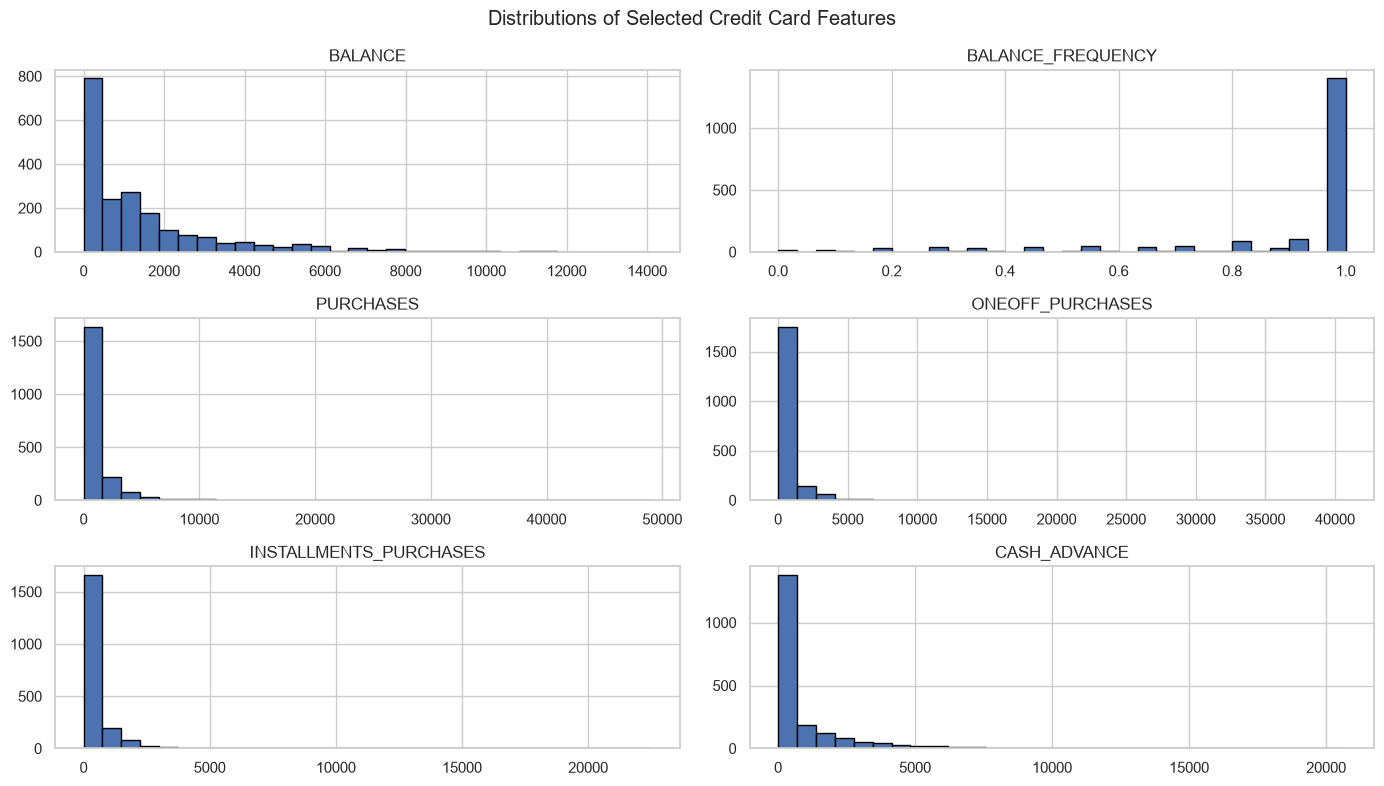

In [13]:
# Plot distributions for up to six important features
eda_cols = X_sample.columns[:min(6, len(X_sample.columns))]

X_sample[eda_cols].hist(
    figsize=(14, 8),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Distributions of Selected Credit Card Features")
plt.tight_layout()
plt.show()

### Distribution Plot Observations

Examine whether the selected financial variables are approximately symmetric or strongly right-skewed. Long right tails indicate that a relatively small number of customers have larger values than most others.

These observations support the use of robust missing-value handling and power transformation. The exact findings should be written after examining the generated plots.

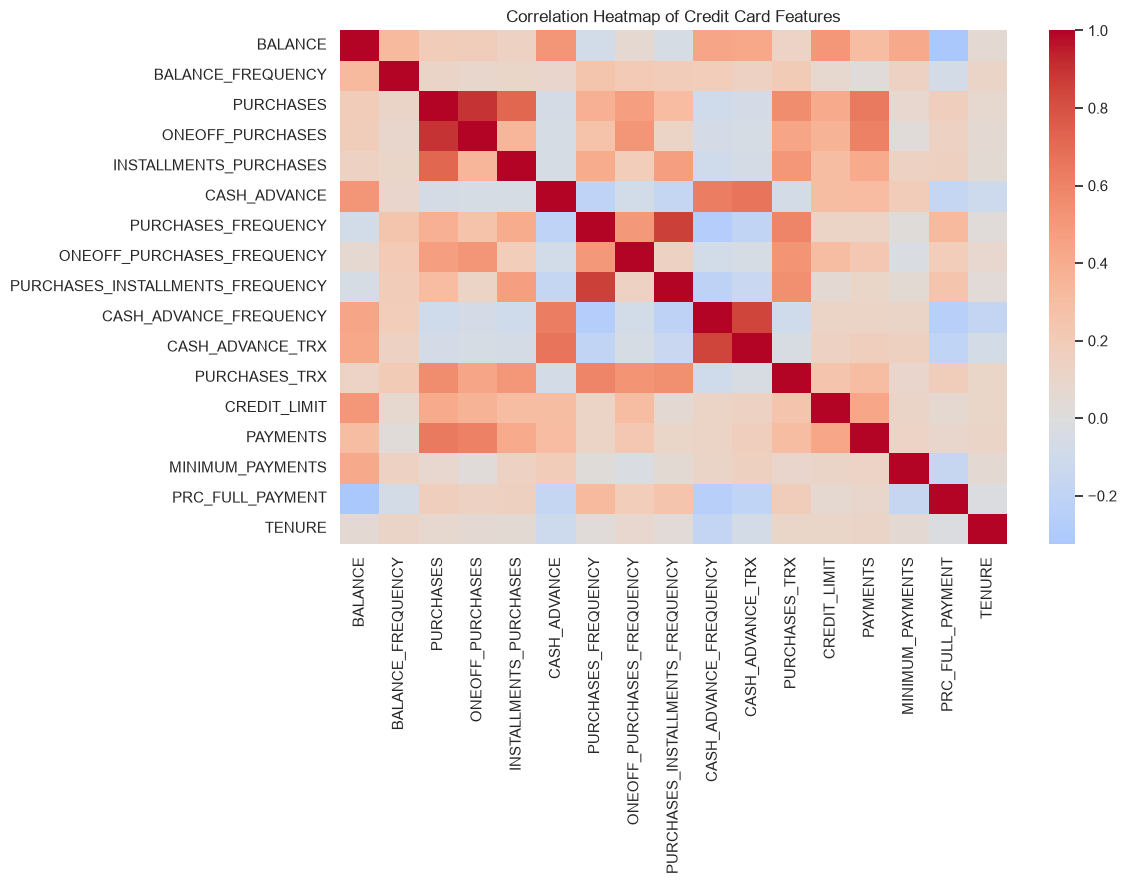

In [14]:
plt.figure(figsize=(12, 9))

sns.heatmap(
    X_sample.corr(),
    cmap="coolwarm",
    center=0,
    annot=False
)

plt.title("Correlation Heatmap of Credit Card Features")
plt.tight_layout()
plt.show()

### Correlation Heatmap Observations

The heatmap displays the direction and strength of linear relationships between features. Strong positive correlations indicate that two attributes tend to increase together, while negative correlations indicate opposing relationships.

Correlation does not establish causation. The heatmap provides context for interpreting the customer segments rather than determining the clusters by itself.